In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

In [2]:
#styling
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

mpl.rcParams['figure.constrained_layout.use'] = True

# Get TESS light curve

In [3]:
import lightkurve as lk

target = 'piMen'
search_result = lk.search_lightcurve('pi Mensae', mission='TESS', author='SPOC', exptime=120)
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,261136679,0.0
1,TESS Sector 04,2018,SPOC,120,261136679,0.0
2,TESS Sector 08,2019,SPOC,120,261136679,0.0
3,TESS Sector 11,2019,SPOC,120,261136679,0.0
4,TESS Sector 12,2019,SPOC,120,261136679,0.0
5,TESS Sector 13,2019,SPOC,120,261136679,0.0
6,TESS Sector 27,2020,SPOC,120,261136679,0.0
7,TESS Sector 28,2020,SPOC,120,261136679,0.0
8,TESS Sector 31,2020,SPOC,120,261136679,0.0


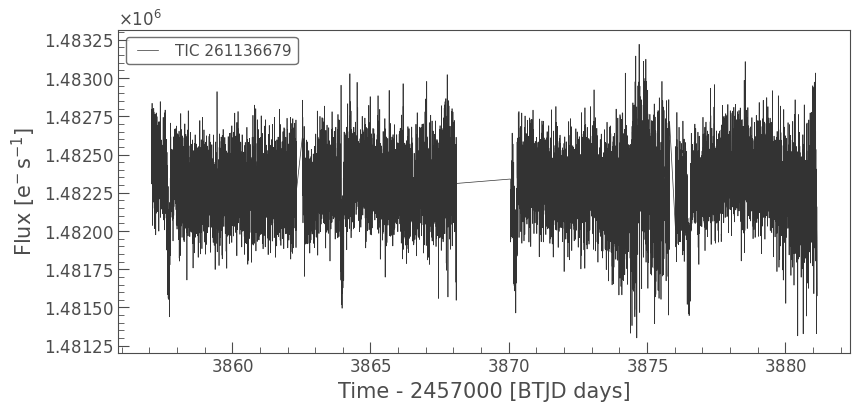

In [4]:
lc = search_result[22].download()
lc = lc.remove_outliers()
lc = lc.remove_nans()
lc.plot();

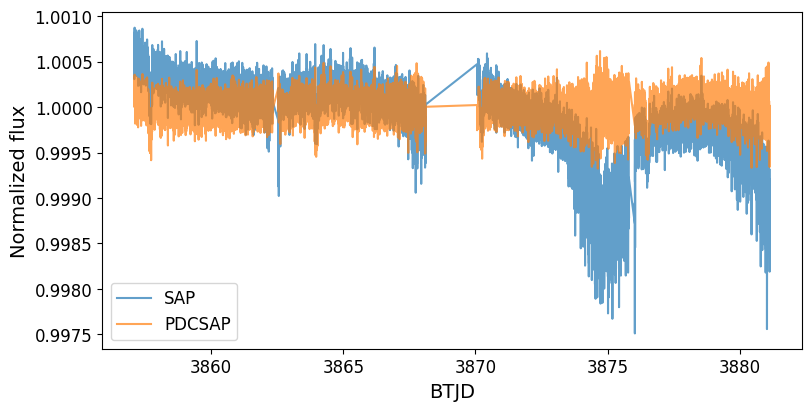

In [5]:
time = np.array(lc.time.value)
sap = np.array(lc.sap_flux.value)
pdcsap = np.array(lc.pdcsap_flux.value)

f = pl.figure(figsize=(8, 4))
pl.plot(time, sap/np.median(sap), alpha=0.7, label='SAP')
pl.plot(time, pdcsap/np.median(pdcsap), alpha=0.7, label='PDCSAP')

pl.legend()
pl.xlabel(f'BTJD')
pl.ylabel('Normalized flux')
f.savefig('output/SAP_vs_PDCSAP.pdf')

In [6]:
df_all = pd.DataFrame({'time':lc.time.value+ 2457000.0,
        'flux':lc.pdcsap_flux.value / np.median(lc.pdcsap_flux.value),
        'err':lc.pdcsap_flux_err.value / np.median(lc.pdcsap_flux.value)})

t_offset = 2460800
time = np.array(df_all['time']) - t_offset
flux = np.array(df_all['flux'])
err = np.array(df_all['err'])

In [7]:
T0_pr, T0_pr_e = 2458325.50400 - t_offset, 0.0012   #Transit center T0
P_pr, P_pr_e = 6.2679, 0.00046           #Orbital Period

In [8]:
n_tran_start=np.ceil((time[0]-T0_pr)/P_pr)  #Transit number from T0
n_tran_end=np.floor((time[-1]-T0_pr)/P_pr)
n_tran=np.arange(n_tran_start, n_tran_end+1, 1)
n_tran

array([404., 405., 406., 407.])

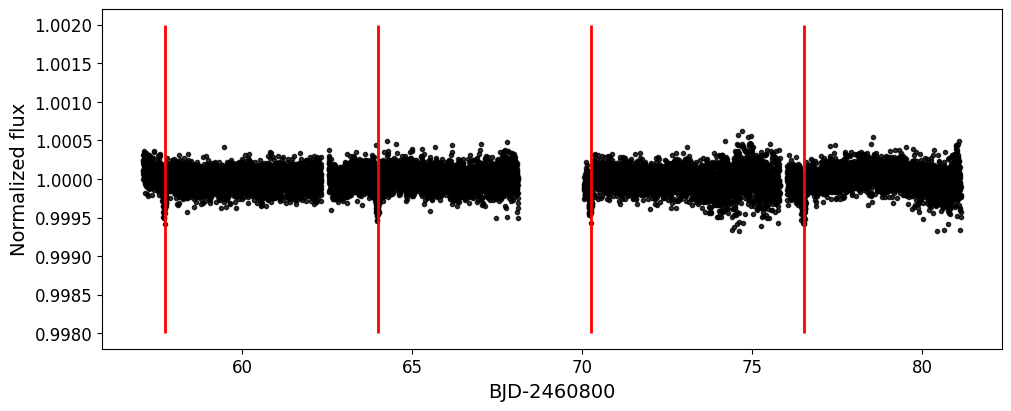

In [9]:
f, ax = pl.subplots(figsize=(10,4))

pl.xlabel(f'BJD-{t_offset}')
pl.ylabel('Normalized flux')

pl.plot(time,flux,".", color='k', alpha=0.8)

for n in n_tran:
    ax.vlines(T0_pr+P_pr*n, 0.998, 1.002, color='r', lw=2)

f.savefig(f'output/{target}_lc_all.pdf')

In [10]:
#extract transit dataset

dfs_transit = []

i=0
for n in n_tran:
    df = df_all[(time > (T0_pr + P_pr*n - 0.3)) &
                (time < (T0_pr + P_pr*n + 0.3))]
    dfs_transit.append(df)

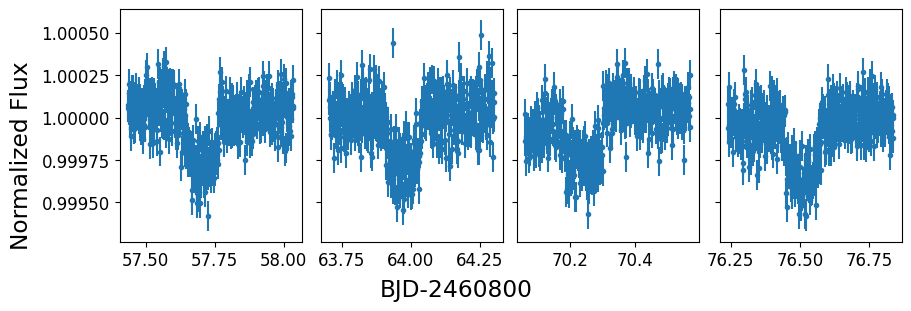

In [11]:
f, axs = pl.subplots(1, len(n_tran), figsize=(9,3), sharey=True)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    axs[int(i%len(n_tran))].ticklabel_format(useOffset=False, axis='y')
    axs[int(i%len(n_tran))].errorbar(df['time']-t_offset, df['flux'], df['err'], fmt='.')
    
f.supxlabel(f'BJD-{t_offset}')
f.supylabel('Normalized Flux')
f.savefig(f'output/{target}_transit_white.pdf')

# imput parameters
From Huang et al. (2018)

In [12]:
#T0_pr, T0_pr_e = 2458325.50400, 0.0012   #Transit center T0
#P_pr, P_pr_e = 6.2679, 0.00046           #Orbital Period

Tc_pr = T0_pr + n_tran_start * P_pr   #Transit center Tc of first transit
Tc_pr_e = np.sqrt(T0_pr_e**2 + (n_tran_start * P_pr_e)**2)
Tc_pr, Tc_pr_e

k_pr, k_pr_e = 0.01703, 0.00025        #Rp/Rs
a_pr, a_pr_e = 13.38, 0.26             #a/Rs
b_pr, b_pr_e = 0.59, 0.02              #impact parameter, b
den_pr, den_pr_e = 1.148, 0.065        #stellar density

In [13]:
from ldtk import LDPSetCreator
from ldtk.filters import tess

teff, uteff = 6037, 45
feh, ufeh   = 0.08,  0.03
logg,ulogg =  4.42, 0.03

sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), 
                   filters=[tess])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

In [14]:
u1_pr, u2_pr = list(qd_c[0])
#u1_pr_e, u2_pr_e = list(qd_e[0])

In [15]:
def u_to_q(u1, u2):
    q1 = (u1 + u2)**2
    q2 = u1 / (2 * (u1 + u2))
    return q1, q2

def q_to_u(q1, q2):
    u1 = 2 * np.sqrt(q1) * q2
    u2 = np.sqrt(q1) * (1 - 2*q2)
    return u1, u2

In [16]:
q1_pr, q2_pr = u_to_q(u1_pr, u2_pr)
q1_pr, q2_pr

(0.2883639900771646, 0.36644135792403393)

# Transit model 

In [17]:
from astropy import constants as ascon
def aP_to_den(a, P):
    den = 3 * np.pi * a**3 / ascon.G.cgs.value / (P*24*3600)**2
    return den

def denP_to_a(den, P):
    a3 = ascon.G.cgs.value * (P*24*3600)**2 *den /  (3 * np.pi)
    a = a3 ** (1/3.)
    return a

In [18]:
import batman
def transit_model(parameters, t):

    t0, p, den, b, k, q1, q2 = parameters
    
    u1, u2 = q_to_u(q1, q2)
    a = denP_to_a(den, p)
    inc= np.arccos(b/a)*180/np.pi
    
    params = batman.TransitParams()
    params.t0 = t0    #time of inferior conjunction
    params.per = p    #orbital period
    params.rp = k     #planet radius (in units of stellar radii)
    params.a = a      #semi-major axis (in units of stellar radii)
    params.inc = inc  #orbital inclination (in degrees)
    params.ecc = 0.   #eccentricity
    params.w = 90.    #longitude of periastron (in degrees)
    params.u = [u1, u2] #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  
    flux = m.light_curve(params)
    return flux

In [19]:
tran_params_init=[Tc_pr, P_pr, den_pr, b_pr, k_pr, q1_pr, q2_pr]

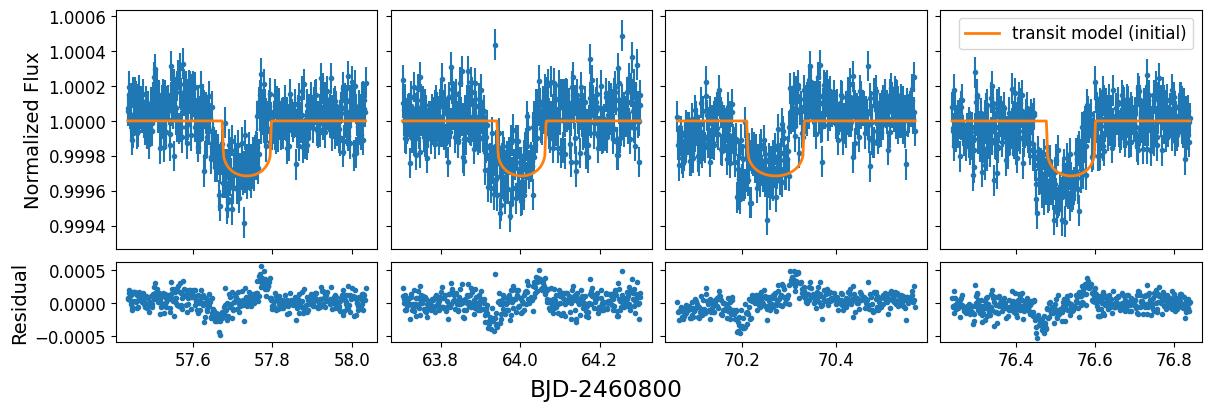

In [20]:
f, axs = pl.subplots(2, len(n_tran), figsize=(12,4), height_ratios=(3,1), sharex='col', sharey='row')
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    time = df['time']-t_offset
    flux = df['flux']
    err = df['err']
    
    tran_model_init = transit_model(tran_params_init, time)
    resid = flux - tran_model_init 
    
    ax = axs[0][int(i%len(n_tran))]
    ax.ticklabel_format(useOffset=False, axis='y')
    ax.errorbar(time, flux, err, fmt='.', zorder=0)
    ax.plot(time,tran_model_init, '-', lw=2, label='transit model (initial)', zorder=1)
    
    ax = axs[1][int(i%len(n_tran))]
    ax.plot(time, resid, '.')

f.supxlabel(f'BJD-{t_offset}')
axs[0][0].set_ylabel('Normalized Flux')
axs[1][0].set_ylabel('Residual')
axs[0][len(n_tran)-1].legend()
    
f.savefig(f'output/{target}_transit_initial.pdf')

# Gaussian Process

In [75]:
import celerite2
from celerite2 import terms

kernel = terms.Matern32Term(sigma=np.std(resid), rho=0.1)

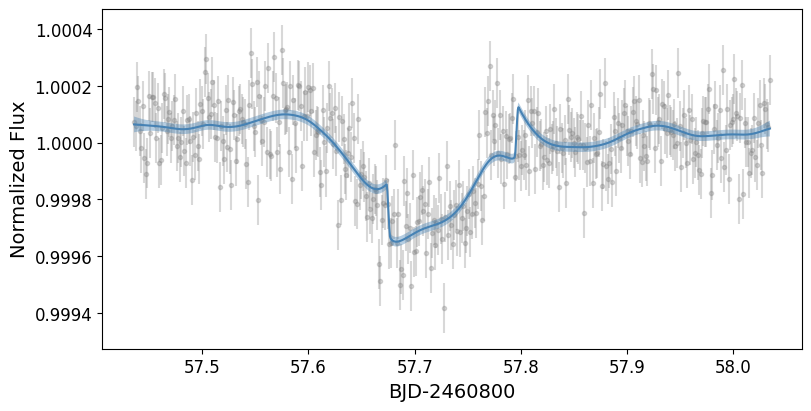

In [103]:
df = dfs_transit[0]
time = np.array(df['time'])-t_offset
flux= np.array(df['flux'])
err = np.array(df['err'])

t_fine=np.linspace(time[0], time[-1], 1000) 
tran_model = transit_model(tran_params_init, time)
tran_model_fine = transit_model(tran_params_init, t_fine)

resid = flux - tran_model

gp = celerite2.GaussianProcess(kernel, mean=0)
gp.compute(time, yerr=err) 

pred_mean, pred_var = gp.predict(resid, t_fine, return_var=True)
pred_std = np.sqrt(pred_var)


f, ax = pl.subplots(1, 1, figsize=(8,4))
ax.ticklabel_format(useOffset=False, axis='y')
ax.errorbar(time, flux, err, fmt='.', zorder=0, color='gray', alpha=0.3)

ax.plot(t_fine, tran_model_fine + pred_mean, '-', color='steelblue')
ax.fill_between(t_fine, 
                tran_model_fine + pred_mean+pred_std, 
                tran_model_fine + pred_mean-pred_std,  
                alpha=0.4, color='steelblue', edgecolor="none")

ax.set_xlabel(f'BJD-{t_offset}')
ax.set_ylabel('Normalized Flux')

f.savefig(f'output/{target}_transit_GP_fixhyperparam.pdf')

# preparing parameter set

In [131]:
#tran_params_init=[Tc_pr, P_pr, den_pr, b_pr, k_pr, q1_pr, q2_pr]
theta_init = [np.std(resid), 0.1]  #hyper parameters (theta0, theta1)
 
params_full_init = tran_params_init + theta_init
params_name = 'Tc,P,density,b,Rp_Rs,q1,q2,theta0,theta1'.split(',')
#params_full_init

In [132]:
len_t = len(tran_params_init)
len_theta = len(theta_init)

## preparing function for plotting

In [133]:
def GP_predict(df, params):

    # data
    time = np.array(df['time'])-t_offset
    flux = np.array(df['flux'])
    err  = np.array(df['err'])

    t_fine = np.linspace(time[0], time[-1], 1000)

    # params
    tran_params = params[:len_t]
    theta    = params[len_t:]

    # mean model (transit)
    tran_model = transit_model(tran_params, time)
    tran_model_fine = transit_model(tran_params, t_fine)
    resid = flux - tran_model   

    # GP
    kernel = terms.Matern32Term(sigma=theta[0], rho=theta[1])
    gp = celerite2.GaussianProcess(kernel, mean=0)
    gp.compute(time, yerr = err)

    # prediction
    pred_mean, pred_var = gp.predict(resid, t_fine, return_var=True)
    pred_std = np.sqrt(pred_var)

    pred_df = pd.DataFrame({
        't_fine': t_fine,
        'pred_mean': pred_mean,
        'pred_std': pred_std,
        'tran_model':tran_model_fine,
        'tran_pred':tran_model_fine+pred_mean
    })

    return pred_df

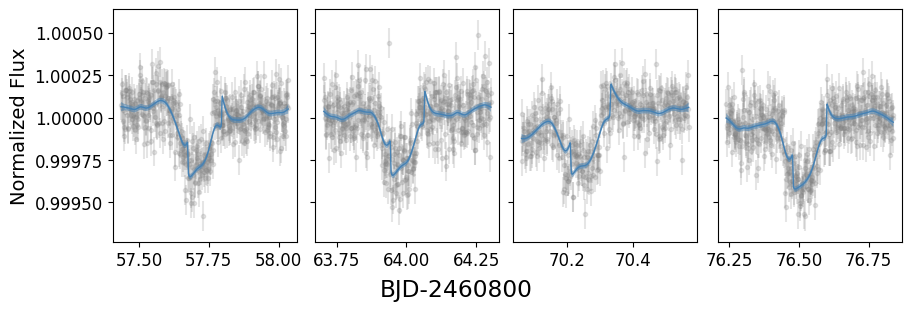

In [134]:
f, axs = pl.subplots(1, len(n_tran), figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    ax = axs[int(i%len(n_tran))]
    ax.ticklabel_format(useOffset=False, axis='y')
    ax.errorbar(df['time']-t_offset, df['flux'], df['err'], 
                fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, params_full_init)
    ax.plot(pred_df['t_fine'], pred_df['tran_pred'], 
            '-', color='steelblue', lw=1, zorder=1)
    ax.fill_between(pred_df['t_fine'], 
                    pred_df['tran_pred']+pred_df['pred_std'],
                    pred_df['tran_pred']-pred_df['pred_std'],
                    alpha=0.5, color='steelblue', edgecolor="none")
    
f.supxlabel(f'BJD-{t_offset}')

axs[0].set_ylabel('Normalized Flux')
f.savefig(f'output/{target}_transit_GP_initial_4transit.pdf')

# Define log-probability functions

In [80]:
from scipy import stats

def logprior(params_full):
    Tc, P, den, b, k, q1, q2, theta0, theta1 = params_full
    
    lp = 0
    
    if not (Tc_pr-0.2<Tc<Tc_pr+0.2):
        return -np.inf
    
    if not all (0<x<1 for x in [b, k, q1, q2]):
        return -np.inf
    
    if not  (0 < theta0 < 10*np.std(resid)):
        return -np.inf
    
    if not (0.01 < theta1 < 0.5):
        return -np.inf
    
    lp += stats.norm.logpdf(Tc, loc=Tc_pr, scale=Tc_pr_e)
    lp += stats.norm.logpdf(P, loc=P_pr, scale=P_pr_e)
    lp += stats.norm.logpdf(den, loc=den_pr, scale=den_pr_e)
    lp += stats.norm.logpdf(k, loc=k_pr, scale=k_pr_e)
    lp += stats.norm.logpdf(q1, loc=q1_pr, scale=0.1)
    lp += stats.norm.logpdf(q2, loc=q2_pr, scale=0.1)
    
    return lp
    
def logprob(params_full, dfs):
    tran_params = params_full[:len_t]
    theta = params_full[len_t:]

    #logprior
    lp = logprior(params_full)
    if not np.isfinite(lp):
        return -np.inf

    # GP
    kernel = terms.Matern32Term(sigma=theta[0], rho=theta[1])
    gp = celerite2.GaussianProcess(kernel, mean=0)
    
    #loglike
    ll_sum = 0
    for df in dfs:
        time = np.array(df['time'])-t_offset
        flux = np.array(df['flux'])
        err = np.array(df['err'])
        
        tran_model = transit_model(tran_params, time)
        resid = flux - tran_model   
        
        gp.compute(time, yerr=err)
        ll_sum += gp.log_likelihood(resid)
        
    return ll_sum + lp

In [112]:
logprob(params_full_init, dfs_transit)

12630.149839028405

# optimization

In [115]:
import scipy.optimize as op
def neg_logprob(params_full, dfs):
    return -logprob(params_full, dfs)

result = op.minimize(neg_logprob, params_full_init,
                     args=(dfs_transit,), method='Powell')

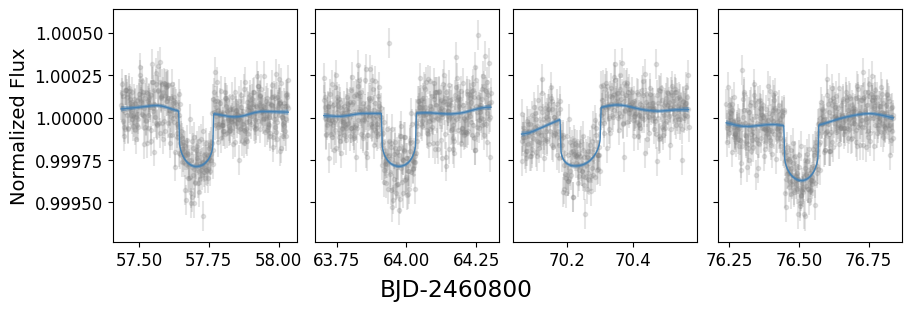

In [117]:
f, axs = pl.subplots(1, len(n_tran), figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    ax = axs[int(i%len(n_tran))]
    ax.ticklabel_format(useOffset=False, axis='y')
    ax.errorbar(df['time']-t_offset, df['flux'], df['err'], 
                fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, result.x)
    ax.plot(pred_df['t_fine'], pred_df['tran_pred'], 
            '-', color='steelblue', lw=1, zorder=1)
    ax.fill_between(pred_df['t_fine'], 
                    pred_df['tran_pred']+pred_df['pred_std'],
                    pred_df['tran_pred']-pred_df['pred_std'],
                    alpha=0.5, color='steelblue', edgecolor="none")
    
f.supxlabel(f'BJD-{t_offset}')
axs[0].set_ylabel('Normalized Flux')
f.savefig(f'output/{target}_transit_GP_optimize_4transit.pdf')

# MCMC

In [123]:
import emcee

params  = result.x
ndim = len(params)
nwalkers = 64
nsteps=10000

In [124]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, logprob, args=(dfs_transit,))

p0 = [params +  1e-5 * np.random.randn(ndim) for i in range(nwalkers)]

sampler.run_mcmc(p0, nsteps, progress=True)
samples = sampler.get_chain(discard=0, thin=1)

100%|███████████████████████████████████████| 10000/10000 [18:13<00:00,  9.14it/s]


In [105]:
print("Mean acceptance fraction: {0:.3f}".format(np.mean(sampler.acceptance_fraction)))
print("Mean autocorrelation time: {0:.3f} steps".format(np.mean(sampler.get_autocorr_time())))

Mean acceptance fraction: 0.425
Mean autocorrelation time: 104.716 steps


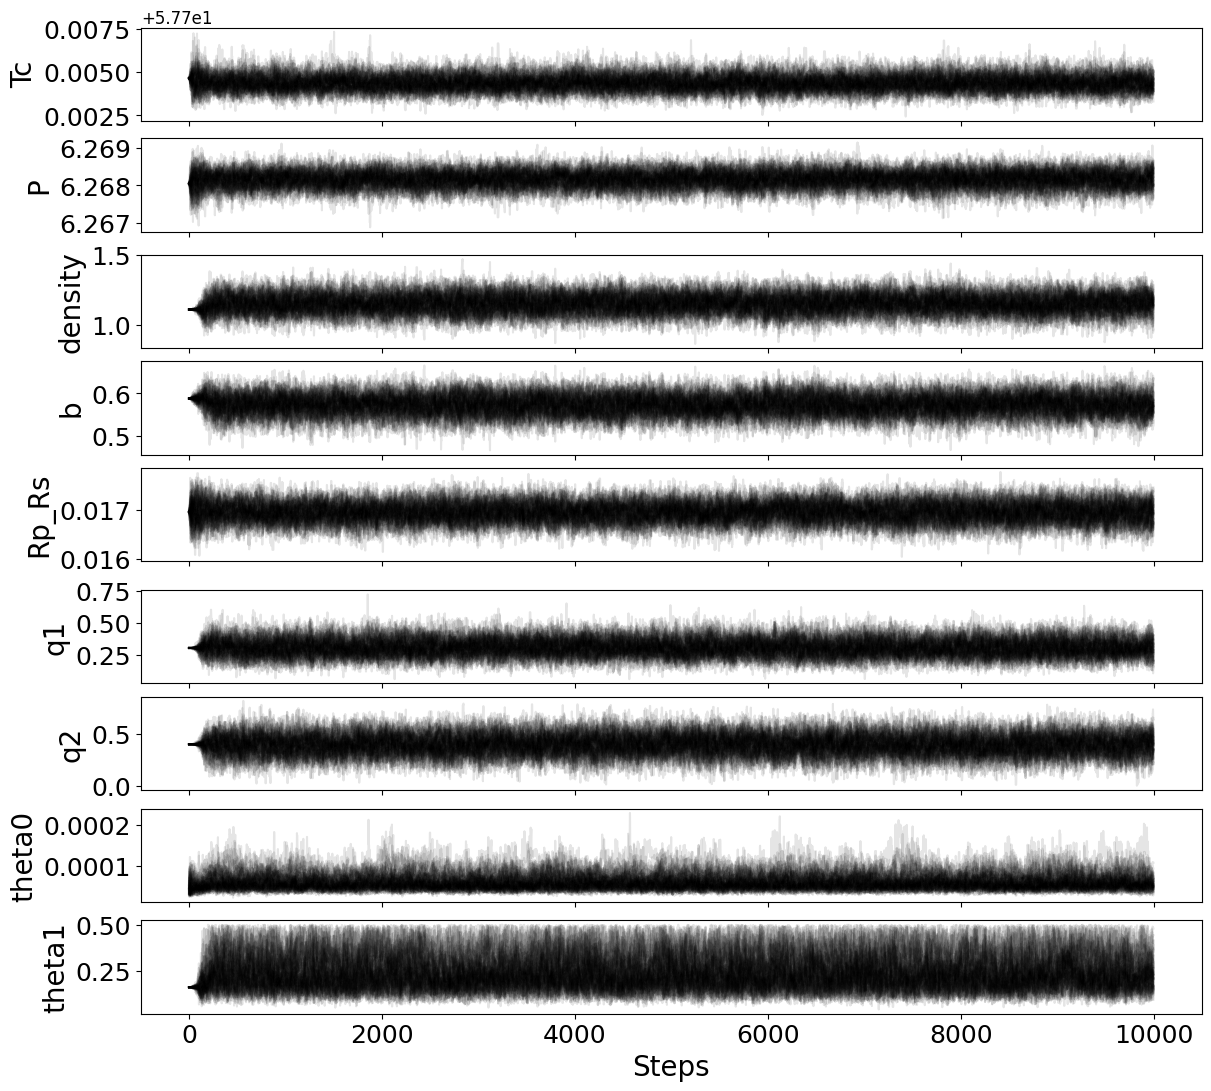

In [125]:
f, ax = pl.subplots(ndim, 1, figsize=(10*1.2,ndim*1.2))

for i in range(ndim):
    ax[i].plot(samples[:, :, i], color='k', alpha=0.1, rasterized=True)
    
    if i==(ndim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)
    
f.savefig(f'output/{target}_chain.pdf')

In [126]:
flat_samples = sampler.get_chain(discard=5000, thin=10, flat=True)

In [127]:
params_full_best=[]
params_full_best_err = []

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)

    params_full_best.append(mcmc[1])
    params_full_best_err.append(np.mean(q))

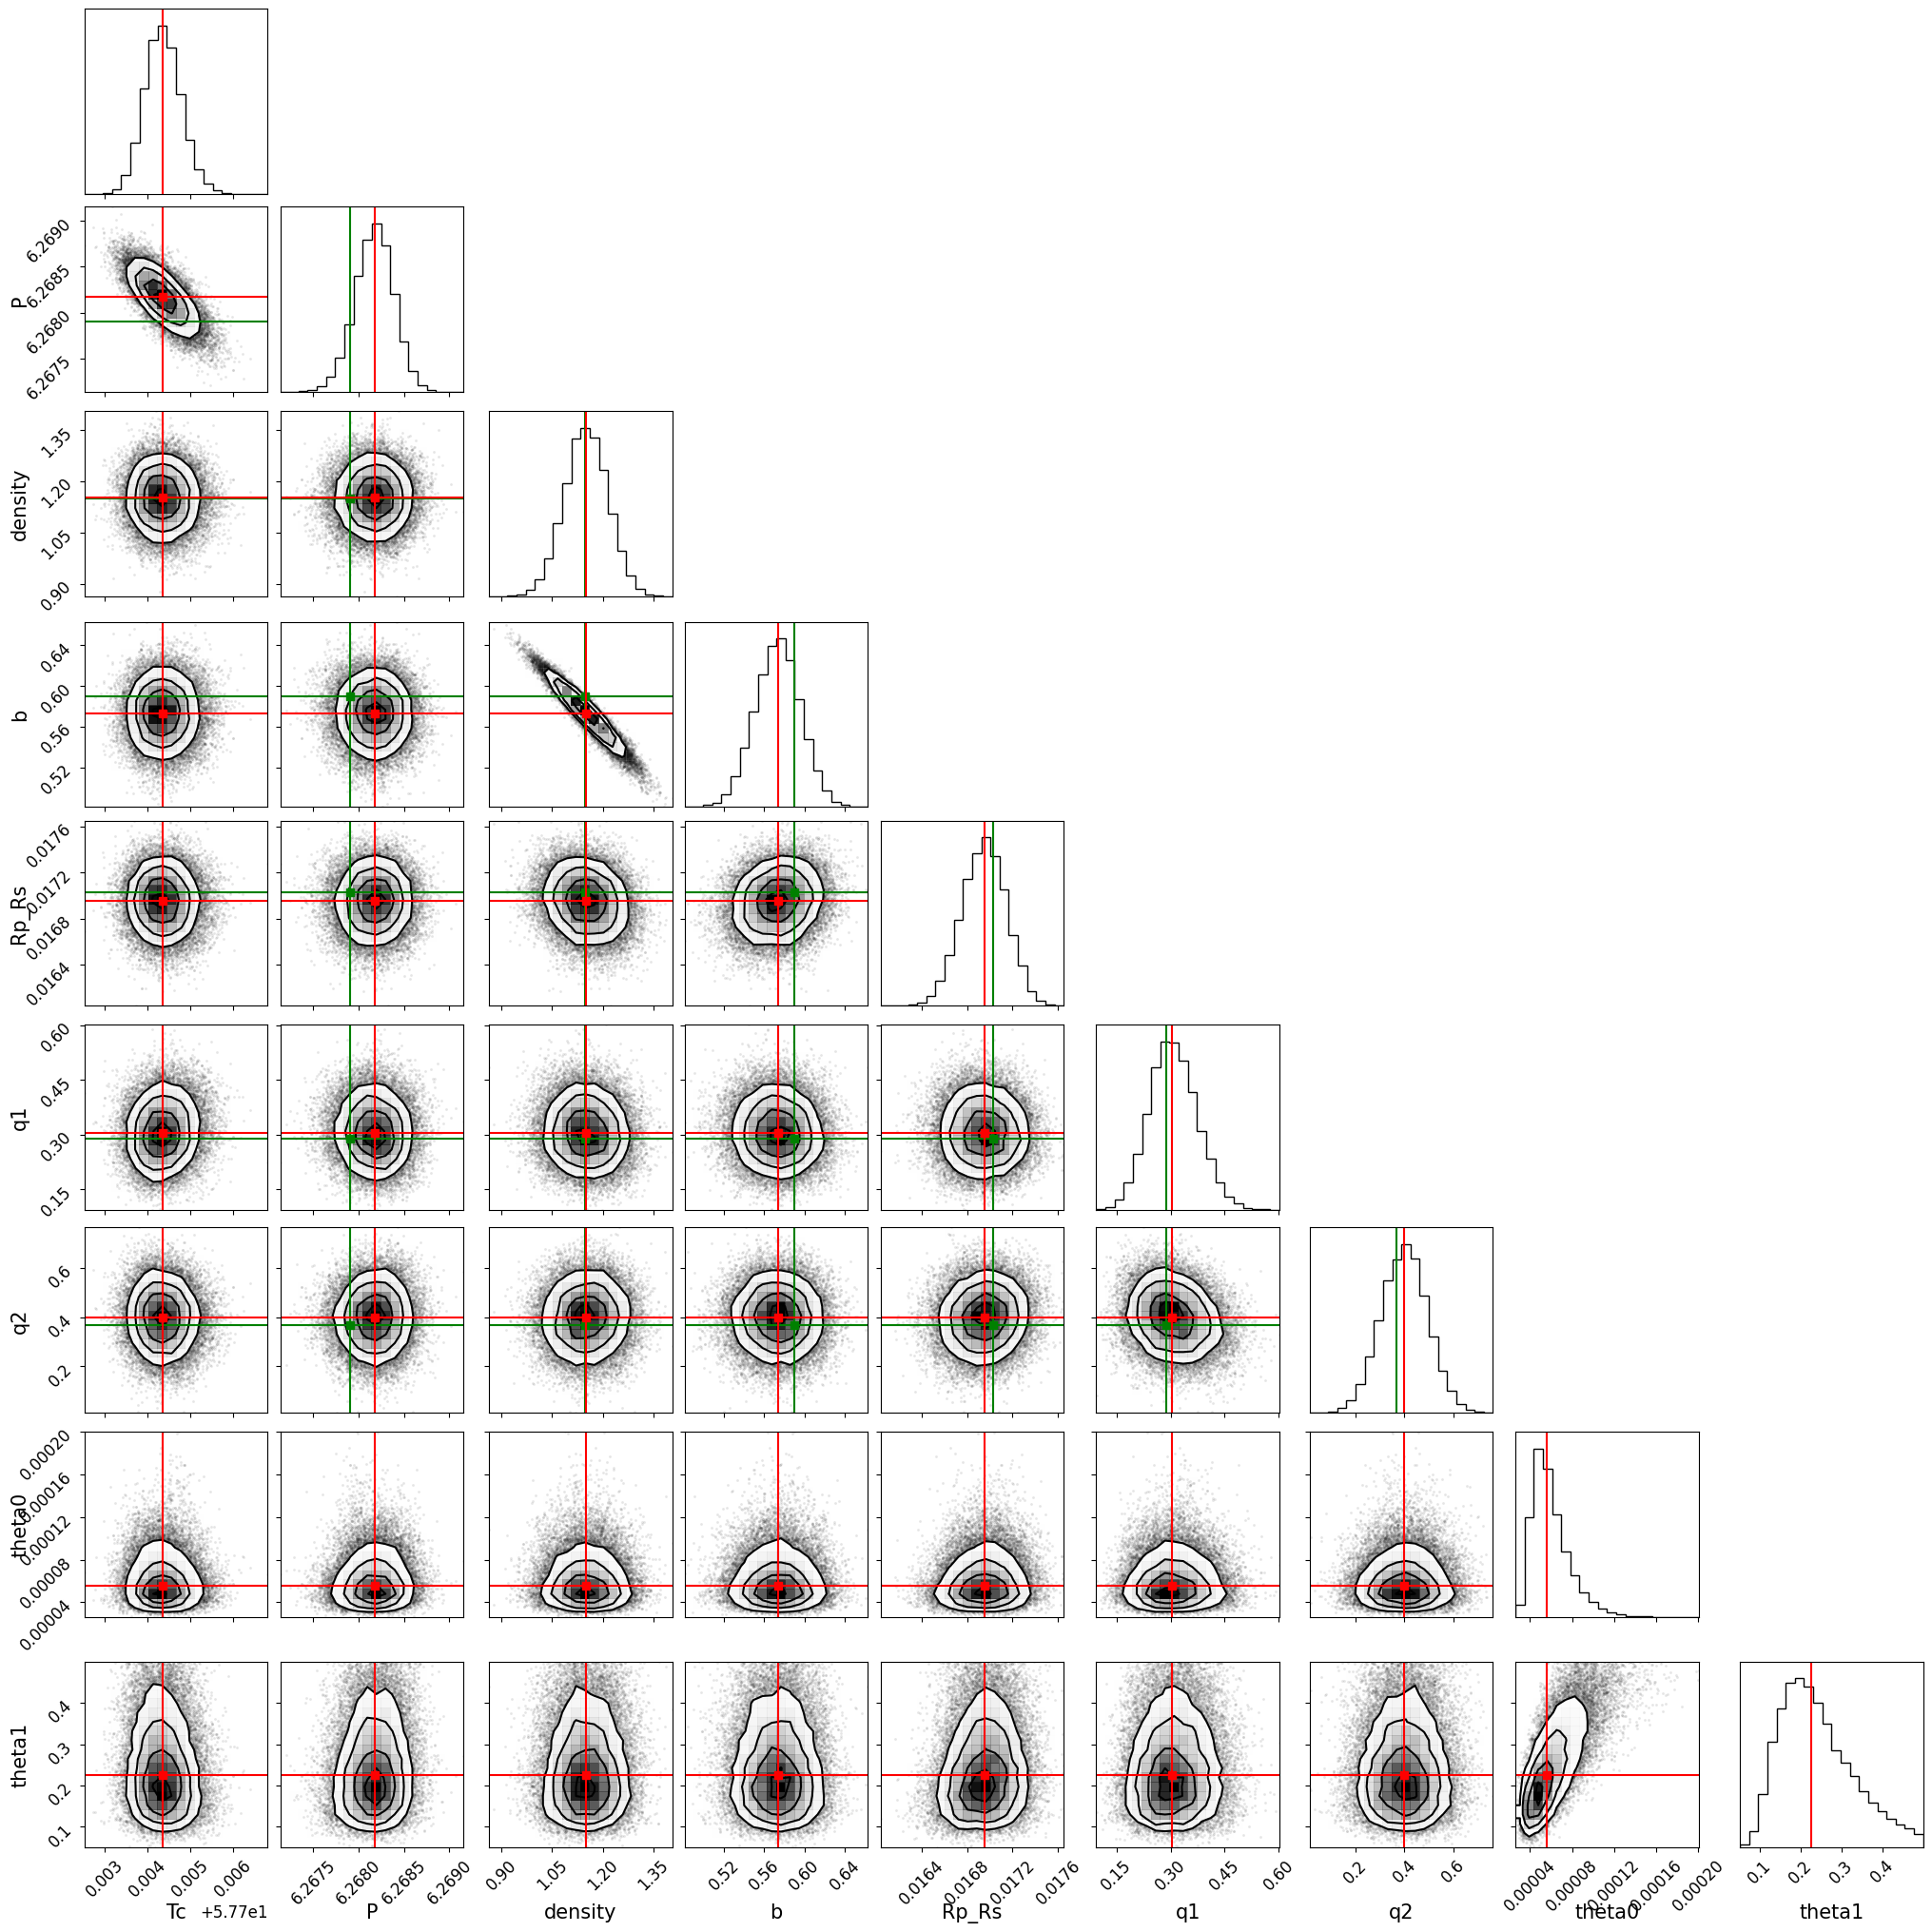

In [129]:
import corner

f = corner.corner(flat_samples, labels=params_name, label_kwargs=dict(fontsize=15))    
axes = np.array(f.axes).reshape((ndim, ndim))

# initial guess
for i in range(len_t):
    ax = axes[i, i]
    ax.axvline(tran_params_init[i], color="g")

for yi in range(len_t):
    for xi in range(yi):
        ax = axes[yi, xi]     
        ax.axvline(tran_params_init[xi], color="g")
        ax.axhline(tran_params_init[yi], color="g")
        ax.plot(tran_params_init[xi], tran_params_init[yi], "sg")

# best parameters
for i in range(ndim):
    ax = axes[i, i]
    ax.axvline(params_full_best[i], color="r")

for yi in range(ndim):
    for xi in range(yi):
        ax = axes[yi, xi]     
        ax.axvline(params_full_best[xi], color="r")
        ax.axhline(params_full_best[yi], color="r")
        ax.plot(params_full_best[xi], params_full_best[yi], "sr")

f.savefig(f'output/{target}_corner.pdf')

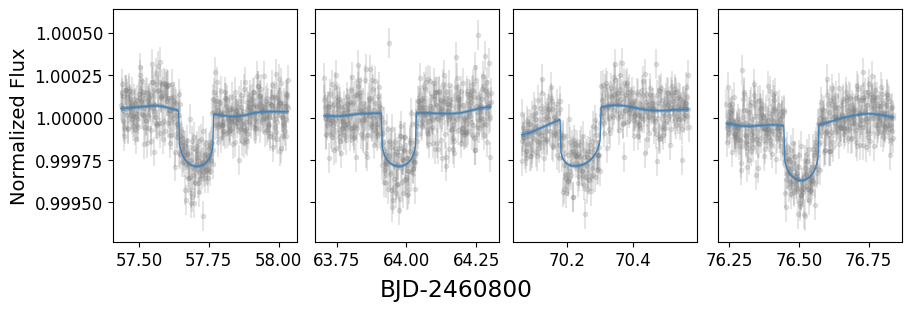

In [128]:
f, axs = pl.subplots(1, len(n_tran), figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    ax = axs[int(i%len(n_tran))]
    ax.ticklabel_format(useOffset=False, axis='y')
    ax.errorbar(df['time']-t_offset, df['flux'], df['err'], fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, params_full_best)
    ax.plot(pred_df['t_fine'], pred_df['tran_pred'], '-', color='steelblue', lw=1, zorder=1)
    ax.fill_between(pred_df['t_fine'], 
                               pred_df['tran_pred']+pred_df['pred_std'],
                               pred_df['tran_pred']-pred_df['pred_std'],
                               alpha=0.5, color='steelblue', edgecolor="none")
    
f.supxlabel(f'BJD-{t_offset}')
axs[0].set_ylabel('Normalized Flux')
f.savefig(f'output/{target}_transit_GP_best_4transit.pdf')

In [130]:
print("Parameter   Initial    Best      Err")
print("----------------------------------------")

for name, ini, best, err in zip(params_name[:len_t],
                                tran_params_init,
                                params_full_best[:len_t],
                                params_full_best_err[:len_t]):
    
    print(f"{name:8s}   {ini:7.5f}   {best:7.5f}   {err:7.5f}")

Parameter   Initial    Best      Err
----------------------------------------
Tc         57.73560   57.70435   0.00042
P          6.26790   6.26817   0.00021
density    1.14800   1.15115   0.06329
b          0.59000   0.57344   0.02247
Rp_Rs      0.01703   0.01695   0.00019
q1         0.28836   0.30525   0.06509
q2         0.36644   0.40024   0.09531
